In [1]:
from pathlib import Path
from fastai.vision.all import *

searches = 'angry','happy','relaxed','sad'
path = Path('/kaggle/input/datasets/mohitagarwal17/dog-emotion-dataset/Dog Emotion')

In [ ]:
from sklearn.model_selection import train_test_split

path = Path('/kaggle/input/datasets/mohitagarwal17/dog-emotion-dataset/Dog Emotion')
files = get_image_files(path)
train_files, test_files = train_test_split(
    files,
    test_size=0.15,
    random_state=29)
print(len(train_files))
print(len(test_files))

3355
593


In [3]:
# dls = DataBlock(
#     blocks=(ImageBlock, CategoryBlock),
#     get_items=noop,
#     splitter=RandomSplitter(valid_pct=0.2, seed=42),
#     get_y=parent_label,
#     batch_tfms=aug_transforms(),
#     item_tfms=[Resize(224, method='squish')]
# ).dataloaders(train_files, bs=32)
# import matplotlib.pyplot as plt
# plt.style.use("default")
# dls.show_batch(max_n=6)

In [4]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=noop,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(400, method='pad', pad_mode='reflection')],
    batch_tfms=aug_transforms(mult=1.0,
                              do_flip=True,
                              flip_vert=False,
                              max_rotate=15.0,
                              min_zoom=1.0,
                              max_zoom=1.1,
                              max_lighting=0.2,
                              max_warp=0.1)
).dataloaders(train_files, bs=60)

learn = vision_learner(dls, 
                       'convnext_tiny',
                       loss_func=LabelSmoothingCrossEntropy(),
                       metrics=error_rate, 
                       wd=0.1).to_fp16()

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

In [5]:
# suggested_lr = learn.lr_find()

In [6]:
from fastai.callback.tracker import SaveModelCallback

learn.fine_tune(
    10,
    base_lr=1e-2,
    cbs=SaveModelCallback(monitor='valid_loss', fname='best_phase1')
)

epoch,train_loss,valid_loss,error_rate,time
0,1.708215,1.109336,0.377049,00:49


Better model found at epoch 0 with valid_loss value: 1.1093355417251587.


epoch,train_loss,valid_loss,error_rate,time
0,0.962975,0.730760,0.174367,00:52
1,0.782802,0.750651,0.178838,00:54
2,0.688868,0.696802,0.169896,00:52
3,0.606483,0.650669,0.125186,00:53
4,0.534658,0.572461,0.113264,00:53
5,0.481146,0.558190,0.092399,00:53
6,0.442890,0.552307,0.093890,00:53
7,0.416339,0.522253,0.089419,00:53
8,0.398141,0.518517,0.077496,00:53
9,0.391422,0.516521,0.077496,00:53


Better model found at epoch 0 with valid_loss value: 0.7307597994804382.
Better model found at epoch 2 with valid_loss value: 0.6968021988868713.
Better model found at epoch 3 with valid_loss value: 0.6506689190864563.
Better model found at epoch 4 with valid_loss value: 0.5724611878395081.
Better model found at epoch 5 with valid_loss value: 0.5581899285316467.
Better model found at epoch 6 with valid_loss value: 0.5523068904876709.
Better model found at epoch 7 with valid_loss value: 0.5222527384757996.
Better model found at epoch 8 with valid_loss value: 0.5185167789459229.
Better model found at epoch 9 with valid_loss value: 0.5165209174156189.


In [14]:
learn.load('best_phase1')
learn.unfreeze()

learn.fit_one_cycle(
    5,
    lr_max=slice(1e-6, 1e-3),
    cbs=SaveModelCallback(monitor='valid_loss', fname='best_phase2')
)

/usr/local/lib/python3.12/dist-packages/fastai/learner.py:67: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")


epoch,train_loss,valid_loss,error_rate,time
0,0.388259,0.515480,0.077496,00:55
1,0.384452,0.510224,0.071535,00:53
2,0.384435,0.512687,0.073025,00:54
3,0.382128,0.509194,0.071535,00:54
4,0.380786,0.509677,0.074516,00:54


Better model found at epoch 0 with valid_loss value: 0.5154803991317749.
Better model found at epoch 1 with valid_loss value: 0.5102244019508362.
Better model found at epoch 3 with valid_loss value: 0.5091938376426697.


In [15]:
test_dl = dls.test_dl(test_files, with_labels=True)
loss, err = learn.validate(dl=test_dl)
accuracy = (1-err)*100
print(f"Test Images: {len(test_files)}")
print(f"Correct Predictions: {round(accuracy*len(test_files)/100)}")
print(f"Incorrect Predictions: {len(test_files)-round(accuracy*len(test_files)/100)}")
print(f"Accuracy: {accuracy:.2f}%")

Test Images: 593
Correct Predictions: 550
Incorrect Predictions: 43
Accuracy: 92.75%


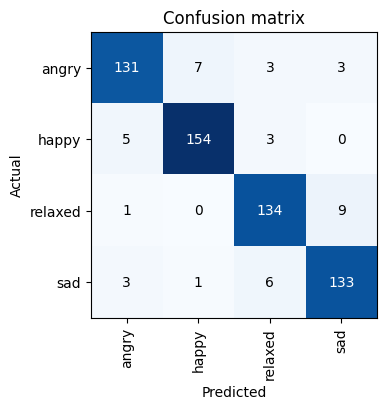

In [8]:
interp = ClassificationInterpretation.from_learner(
    learn,
    dl=test_dl)
interp.plot_confusion_matrix(figsize=(4,4))

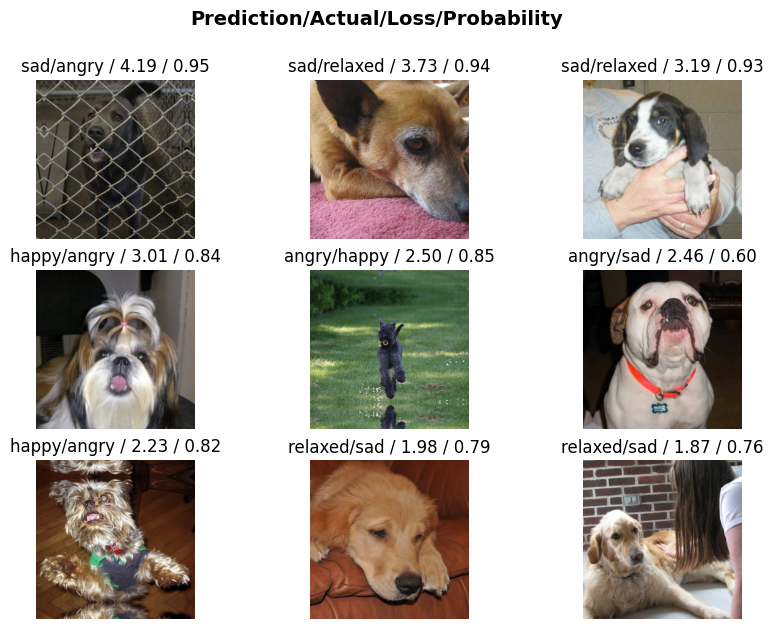

In [9]:
interp.plot_top_losses(9, figsize=(10,7))

In [16]:
from sklearn.metrics import classification_report

preds, targs = learn.tta(dl=test_dl)

y_pred = preds.argmax(dim=1).numpy()
y_true = targs.numpy()

print(classification_report(
    y_true,
    y_pred,
    target_names=dls.vocab
))

epoch,train_loss,valid_loss,error_rate,time


<div></div>

              precision    recall  f1-score   support

       angry       0.94      0.92      0.93       144
       happy       0.96      0.96      0.96       162
     relaxed       0.94      0.92      0.93       144
         sad       0.91      0.95      0.93       143

    accuracy                           0.94       593
   macro avg       0.94      0.94      0.94       593
weighted avg       0.94      0.94      0.94       593



In [17]:
# Pass any individual image path to see it in action
img = PILImage.create('/kaggle/input/datasets/mohitagarwal17/dog-img/angry dog.png')
emotion, cl_idx, probs = learn.predict(img)
print(f"This dog looks: {emotion} ({probs[cl_idx]*100:.2f}% confidence)")
# Pass any individual image path to see it in action
img = PILImage.create('/kaggle/input/datasets/mohitagarwal17/dog-img/happy dog.png')
emotion, cl_idx, probs = learn.predict(img)
print(f"This dog looks: {emotion} ({probs[cl_idx]*100:.2f}% confidence)")
# Pass any individual image path to see it in action
img = PILImage.create('/kaggle/input/datasets/mohitagarwal17/dog-img/sad dog.png')
emotion, cl_idx, probs = learn.predict(img)
print(f"This dog looks: {emotion} ({probs[cl_idx]*100:.2f}% confidence)")# Pass any individual image path to see it in action
img = PILImage.create('/kaggle/input/datasets/mohitagarwal17/dog-img/relaxed dog.png')
emotion, cl_idx, probs = learn.predict(img)
print(f"This dog looks: {emotion} ({probs[cl_idx]*100:.2f}% confidence)")

This dog looks: angry (94.18% confidence)


This dog looks: happy (92.22% confidence)


This dog looks: sad (80.91% confidence)


This dog looks: relaxed (40.30% confidence)


In [18]:
learn.export('emotion 94 after tta%.pkl')